# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [5]:
%pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------------------------ --- 1.6/1.7 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 7.8 MB/s  0:00:00

   ---------------------------------------- 0/3 [regex]
   ------------- -------------------------- 1/3 [click]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   ------

In [6]:
ROLL_NO = 1024170165          # <-- your full roll number
NAME = "Samriddhi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [7]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [8]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [9]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170165   Name: Samriddhi   Fingerprint: 273C8B3B   Tickets: 12

Ticket_ID                                                                  Ticket_Text
      T01             The projector was working yesterday. I have tried several times!
      T02                The student portal crashes while opening. Can you check this?
      T03                   The Wi-Fi is showing an error. I have tried several times!
      T04                                       Only 2 of 30 PCs boot after 3.5 hours.
      T05          VPN failed to open after restarting the system. Can you check this?
      T06             The MATLAB crashes while opening. The same problem occurs again.
      T07                                 See https://lms.thapar.edu/help for details.
      T08                          The MATLAB is showing an error. Can you check this?
      T09                                        Nothing works and nobody has replied.
      T10                        The VPN is runni

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [10]:

# Q1: Text Preprocessing

results = []

# Process every ticket
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    processed = process_ticket(text)

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(processed["sentences"]),
        "Tokens": len(processed["tokens"]),
        "Punctuation": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique_Tokens": len(set(processed["tokens"])),
        "Final_Tokens": len(processed["final"])
    })

# Create the statistics table
stats_df = pd.DataFrame(results)

# Add a total row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": stats_df["Sentences"].sum(),
    "Tokens": stats_df["Tokens"].sum(),
    "Punctuation": stats_df["Punctuation"].sum(),
    "Stopwords": stats_df["Stopwords"].sum(),
    "Unique_Tokens": None,
    "Final_Tokens": stats_df["Final_Tokens"].sum()
}

stats_df = pd.concat(
    [stats_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print("PREPROCESSING STATISTICS")
print(stats_df.to_string(index=False))

# Display detailed preprocessing for one selected ticket
selected_ticket = FOCUS[0]

ticket_text = df.loc[
    df["Ticket_ID"] == selected_ticket, "Ticket_Text"
].iloc[0]

processed = process_ticket(ticket_text)

print("\nSELECTED TICKET:", selected_ticket)
print("Original text:", ticket_text)
print("Tokens:", processed["tokens"])
print("Punctuation tokens:", processed["punct"])
print("Stopwords:", processed["stops"])
print("Final tokens:", processed["final"])


PREPROCESSING STATISTICS
Ticket_ID  Sentences  Tokens  Punctuation  Stopwords Unique_Tokens  Final_Tokens
      T01          2      12            2          4            12             6
      T02          2      12            2          5            12             5
      T03          2      13            2          5            13             6
      T04          1      10            1          3            10             6
      T05          2      14            2          6            14             6
      T06          2      12            2          5            10             5
      T07          1       7            2          1             7             4
      T08          2      12            2          6            12             4
      T09          1       7            1          2             7             4
      T10          2      11            2          4            10             5
      T11          2      10            4          2             9             4
   

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens like “n't” and “'s” are not complete words. They come from contractions such as “isn't” and “it's”, which NLTK's tokenizer splits into smaller parts.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [11]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

# Q2: Regex Extraction and Replacement

import re

# Extract patterns from all tickets
for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print("\nTicket ID:", row["Ticket_ID"])
    print("Original text:", text)

    # 1. Words longer than 5 letters
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    print("Words longer than 5 letters:", long_words)

    # 2. Numbers, decimals, and version numbers
    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)
    print("Numbers:", numbers)

    # 3. Capitalized words
    capitalized = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
    print("Capitalized words:", capitalized)

    # 4. Words beginning with a vowel
    vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)
    print("Words beginning with a vowel:", vowel_words)

    # 5. Replace email addresses
    replaced_email = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )
    print("Email replaced:", replaced_email)

    # 6. Replace URLs
    replaced_url = re.sub(
        r"https?://\S+|www\.\S+",
        "<URL>",
        text
    )
    print("URL replaced:", replaced_url)

    # 7. Replace phone numbers
    replaced_phone = re.sub(
        r"(?<!\w)(?:\+?\d[\d ()-]{7,}\d)(?!\w)",
        "<PHONE>",
        text
    )
    print("Phone replaced:", replaced_phone)



Ticket ID: T01
Original text: The projector was working yesterday. I have tried several times!
Words longer than 5 letters: ['projector', 'working', 'yesterday', 'several']
Numbers: []
Capitalized words: ['The', 'I']
Words beginning with a vowel: ['I']
Email replaced: The projector was working yesterday. I have tried several times!
URL replaced: The projector was working yesterday. I have tried several times!
Phone replaced: The projector was working yesterday. I have tried several times!

Ticket ID: T02
Original text: The student portal crashes while opening. Can you check this?
Words longer than 5 letters: ['student', 'portal', 'crashes', 'opening']
Numbers: []
Capitalized words: ['The', 'Can']
Words beginning with a vowel: ['opening']
Email replaced: The student portal crashes while opening. Can you check this?
URL replaced: The student portal crashes while opening. Can you check this?
Phone replaced: The student portal crashes while opening. Can you check this?

Ticket ID: T03
Ori

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Many capitalized words are capitalized only because they appear at the beginning of a sentence, such as “The” and “Please.” They are not proper nouns; their capitalization is due to sentence position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
# Your code
# Q3: Custom Tokenization

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern that preserves special text elements
pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"                       # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"   # Email addresses
    r"\+?\d[\d ()-]{7,}\d|"                              # Phone numbers
    r"\d+(?:\.\d+)+|"                                    # Decimals and versions
    r"[A-Za-z]+(?:-[A-Za-z]+)*(?:'[A-Za-z]+)?|"          # Words, hyphens, contractions
    r"\d+|"                                               # Integers
    r"[^\w\s]"                                            # Remaining punctuation
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Run on the provided TEST_LINES, if defined
try:
    print("CUSTOM TOKENIZATION ON TEST_LINES")
    for line in TEST_LINES:
        print("\nText:", line)
        print("Custom:", my_tokenize(line))
        print("NLTK:", word_tokenize(line))
except NameError:
    print("TEST_LINES is not defined in the current notebook.")


# Run on all generated tickets and compare
print("\nCOMPARISON ON GENERATED TICKETS")

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    print("\nTicket ID:", row["Ticket_ID"])
    print("Original:", text)
    print("Custom tokens:", custom_tokens)
    print("word_tokenize tokens:", nltk_tokens)


CUSTOM TOKENIZATION ON TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The number of tickets tokenized differently depends on the output of both tokenizers. Differences mainly occur with contractions, hyphenated words, and version numbers.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
# Your code

# Q4: Stemming and Lemmatization

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
import pandas as pd

# Step 1: Collect unique final tokens from all tickets
all_final_tokens = []

for text in df["Ticket_Text"]:
    processed = process_ticket(text)
    all_final_tokens.extend(processed["final"])

unique_final_tokens = sorted(set(all_final_tokens))

print("Number of unique final tokens:", len(unique_final_tokens))
print("Unique final tokens:", unique_final_tokens)


# Step 2: Initialize the four methods
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"ing$")
lemmatizer = WordNetLemmatizer()


# Step 3: Get POS tags and convert them to WordNet format
tagged_words = pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# Step 4: Build the comparison table
results = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    results.append({
        "Word": word,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp": regexp_result,
        "WordNet_Lemma": lemma_result
    })

comparison_df = pd.DataFrame(results)


# Step 5: Justify the Regexp Stemmer suffix using dataset words
ing_words = [
    word for word in unique_final_tokens
    if word.endswith("ing") and len(word) > 4
]

print("\nWords in our dataset ending in 'ing':", ing_words)
print("Regexp Stemmer suffix chosen: 'ing'")
print("Justification: Several ticket words ending in 'ing' share this suffix.")


# Step 6: Display only words whose outputs differ
different_words = comparison_df[
    (comparison_df["Porter"] != comparison_df["Lancaster"]) |
    (comparison_df["Porter"] != comparison_df["Regexp"]) |
    (comparison_df["Porter"] != comparison_df["WordNet_Lemma"]) |
    (comparison_df["Lancaster"] != comparison_df["Regexp"]) |
    (comparison_df["Lancaster"] != comparison_df["WordNet_Lemma"]) |
    (comparison_df["Regexp"] != comparison_df["WordNet_Lemma"])
]

print("\nWORDS WITH DIFFERENT OUTPUTS")
print(different_words.to_string(index=False))


Number of unique final tokens: 46
Unique final tokens: ['//lms.thapar.edu/help', '2', '3.5', '30', 'another', 'asap', 'boot', 'check', 'crashes', 'details', 'error', 'failed', 'fixed', 'hours', 'https', 'matlab', 'nobody', 'nothing', 'occurs', 'open', 'opening', 'pcs', 'pls', 'portal', 'problem', 'projector', 'replied', 'reply', 'restarting', 'running', 'see', 'server', 'several', 'showing', 'since', 'slowly', 'solution', 'student', 'system', 'times', 'tried', 'vpn', 'wi-fi', 'working', 'works', 'yesterday']

Words in our dataset ending in 'ing': ['nothing', 'opening', 'restarting', 'running', 'showing', 'working']
Regexp Stemmer suffix chosen: 'ing'
Justification: Several ticket words ending in 'ing' share this suffix.

WORDS WITH DIFFERENT OUTPUTS
     Word    Porter Lancaster    Regexp WordNet_Lemma
  another     anoth     anoth   another       another
  crashes     crash     crash   crashes         crash
  details    detail    detail   details        detail
    error     error     

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming example: “university” may be shortened incorrectly by an aggressive stemmer. Under-stemming example: “working” may remain unchanged by the Regexp Stemmer if the chosen suffix does not match.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS
              Collection  Total Tokens  Unique Tokens    TTR
         S1 (All tokens)           133             72 0.5414
S2 (Without punctuation)           109             67 0.6147
       S3 (Final tokens)            62             46 0.7419
    S4 (Porter stemming)            62             43 0.6935

TOP 10 WORDS IN S1
[('.', 13), ('the', 9), ('?', 6), ('is', 5), ('yesterday', 3), ('can', 3), ('you', 3), ('check', 3), ('this', 3), ('was', 2)]

TOP 10 WORDS IN S3
[('yesterday', 3), ('check', 3), ('working', 2), ('tried', 2), ('several', 2), ('times', 2), ('crashes', 2), ('opening', 2), ('showing', 2), ('error', 2)]


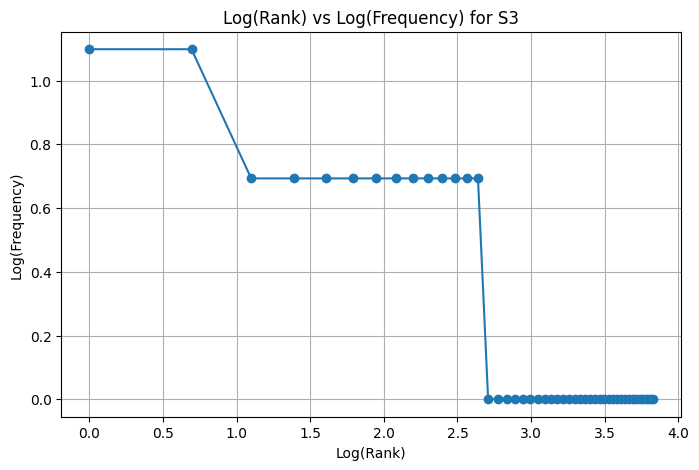


TOP 5 BIGRAMS IN S1
[(('.', 'the'), 4), (('.', 'can'), 3), (('can', 'you'), 3), (('you', 'check'), 3), (('check', 'this'), 3)]

TOP 5 BIGRAMS IN S3
[(('working', 'yesterday'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (('crashes', 'opening'), 2), (('showing', 'error'), 2)]


In [15]:
# Your code

# Q5: Corpus Statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk import FreqDist, bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# Step 1: Create S1, S2, S3, and S4
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    processed = process_ticket(text)

    # S1: All tokens, including punctuation
    S1.extend(processed["tokens"])

    # S2: Tokens without punctuation
    S2.extend([
        token for token in processed["tokens"]
        if not is_punct(token)
    ])

    # S3: Final tokens after removing punctuation and stopwords
    S3.extend(processed["final"])

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Step 2: Calculate total tokens, unique tokens, and TTR
collections = {
    "S1 (All tokens)": S1,
    "S2 (Without punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (Porter stemming)": S4
}

statistics = []

for name, tokens in collections.items():
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    ttr = unique_tokens / total_tokens if total_tokens > 0 else 0

    statistics.append({
        "Collection": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    })

stats_table = pd.DataFrame(statistics)

print("CORPUS STATISTICS")
print(stats_table.to_string(index=False))


# Step 3: Print the top 10 words of S1 and S3
freq_S1 = FreqDist(S1)
freq_S3 = FreqDist(S3)

print("\nTOP 10 WORDS IN S1")
print(freq_S1.most_common(10))

print("\nTOP 10 WORDS IN S3")
print(freq_S3.most_common(10))


# Step 4: Plot log(rank) vs log(frequency) for S3
ranked_words = freq_S3.most_common()

ranks = np.arange(1, len(ranked_words) + 1)
frequencies = np.array([frequency for word, frequency in ranked_words])

log_ranks = np.log(ranks)
log_frequencies = np.log(frequencies)

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", linestyle="-")

plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid()
plt.show()


# Step 5: Print the top 5 bigrams of S1 and S3
bigrams_S1 = FreqDist(bigrams(S1))
bigrams_S3 = FreqDist(bigrams(S3))

print("\nTOP 5 BIGRAMS IN S1")
print(bigrams_S1.most_common(5))

print("\nTOP 5 BIGRAMS IN S3")
print(bigrams_S3.most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because punctuation and stopword removal reduce the total tokens, while stemming combines similar words into common forms. This changes the proportion of unique words in the dataset.